# PC02 — Phân tích đặc trưng RFM và thiết kế cách biểu diễn khách hàng

> **Cách đọc:** Kết quả và nhận xét chính hiển thị trực tiếp. Nhấn **Xem chi tiết** để mở bảng đối chiếu; nhật ký tiến trình cũng được thu gọn. Các phép tính và dữ liệu vẫn được giữ đầy đủ.

## Mục tiêu nghiệp vụ
Hai khách có thể giống nhau về tổng tiền nhưng khác nhau về số lần mua hoặc thời điểm lần mua cuối. Đồng thời, Monetary có thể lớn hàng trăm nghìn trong khi Frequency chỉ vài đơn. Nếu dùng khoảng cách trực tiếp, mô hình có thể phản ánh thang số nhiều hơn hành vi.

PC02 nghiên cứu **dữ liệu đang phân bố ra sao và nên biểu diễn khách thế nào** trước khi thử mô hình. Việc biến đổi phải có lý do, không chọn chỉ vì biểu đồ trông đẹp hoặc mong muốn đủ một số nhóm định trước.

## Các câu hỏi trọng tâm
- Khách một đơn chiếm bao nhiêu và đóng góp giá trị thế nào?
- Đuôi F/M có phải lỗi, hay là những khách đáng nghiên cứu?
- F, M và khoảng lịch sử quan sát liên hệ ra sao?
- StandardScaler và log làm thay đổi khoảng cách giữa khách như thế nào?
- Biến hành vi nào cung cấp góc nhìn mới, biến nào trùng thông tin RFM?

Kết quả là cơ sở cho hai thí nghiệm TN1/TN2 trên cùng tập khách. **Chưa chấm điểm RFM 1–5, chưa đặt tên cụm và chưa suy nguyên nhân kinh doanh.**


## Cách đọc thuật ngữ và kết quả

- **Recency:** số ngày từ đơn delivered gần nhất đến 31/12/2022.
- **Frequency:** số đơn delivered đủ điều kiện của một khách.
- **Monetary:** tổng tiền sau giảm giá của các đơn đó, chưa là lợi nhuận hoặc thực thu.
- **Cụm:** nhóm khách do thuật toán tạo; mã nhóm chỉ để nhận diện.
- **Mẫu số:** tổng khách hoặc tổng đơn dùng để tính tỷ lệ; luôn đọc đúng phạm vi cạnh bảng.

Các ký hiệu và công thức cần thiết được giải thích ngay tại mục sử dụng.


## Chuẩn bị môi trường và nguồn dữ liệu

Notebook tự tìm thư mục dự án và nạp notebook hỗ trợ 00. RFM được tính từ raw/common và đối soát trực tiếp với dòng hàng nguồn; không đọc kết quả phân cụm cũ hay JSON mô hình. PC01–PC02 chưa huấn luyện. PC03 thử và chọn mô hình mới; PC04–PC06 tự huấn luyện lại khi chạy ở kernel riêng. Trong cùng kernel, các phép tính được dùng lại từ bộ nhớ.

Mặc định lượt là combined_v1. Nếu CSV của lượt đó đã tồn tại và khác kết quả mới, chương trình dừng lưu; chọn tên DATATHON_MODEL_RUN mới hoặc chủ động sao lưu/xóa CSV cũ. Kết quả cũ không quyết định lựa chọn mô hình.


In [1]:
from pathlib import Path
import sys, json
sys.dont_write_bytecode = True
from decimal import Decimal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown

import os

start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents)
             if (path / "notebook/ham_dung_chung.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở thư mục gốc của dự án hoặc đặt RETAIL_ANALYTICS_ROOT.")
sys.path.insert(0, str(ROOT / "notebook"))

# Nạp định nghĩa hỗ trợ riêng, không sửa file Python dùng chung của nhóm.
_support_path = ROOT / 'notebook/05_phan_khuc_khach_hang/00_ham_ho_tro_phan_cum.ipynb'
_support_doc = json.loads(_support_path.read_text(encoding='utf-8'))
for _cell_index, _cell in enumerate(_support_doc['cells']):
    if _cell['cell_type'] == 'code':
        exec(compile(''.join(_cell['source']), f'{_support_path}:cell{_cell_index+1}', 'exec'), globals())

from ham_dung_chung import segmentation_study
sys.dont_write_bytecode = True
Study = phan_cum_tich_hop().Study
share_table = segmentation_study().share_table
concentration = segmentation_study().concentration
distribution = segmentation_study().distribution
from ham_dung_chung import rfm_features
rfm = rfm_features().rfm
from ham_dung_chung import segmentation_transform
feature_matrix = segmentation_transform().feature_matrix
from ham_dung_chung import segmentation_defaults
require = segmentation_defaults().require
FEATURES = segmentation_defaults().FEATURES
CUTOFF = segmentation_defaults().CUTOFF
MODEL_LABEL = os.environ.get("DATATHON_MODEL_RUN", "combined_v1")
study = Study(ROOT, "PC02")
pd.set_option('display.max_columns',20)
print('Phần phân tích:', study.part, '| Lượt mô hình:', MODEL_LABEL)

Phần phân tích: PC02 | Lượt mô hình: combined_v1


## PC02.1 — Đọc phân bố, phân vị và độ lệch của RFM

Xem trung vị và các phân vị thay vì chỉ nhìn trung bình. Trung vị là mức giữa khi sắp các giá trị tăng dần. P90 là mốc mà khoảng 90% giá trị nằm ở hoặc dưới đó; P99 tương tự cho khoảng 99%. Một ít khách mua rất nhiều có thể kéo trung bình lên, khiến nó không còn giống mức mua của phần lớn khách.

Phân vị có thể nằm giữa hai giá trị quan sát, không nhất thiết trùng với giá trị của một khách cụ thể.

Độ lệch chuẩn cho biết mức phân tán quanh trung bình. Bảng thống kê pandas và StandardScaler dùng hai quy ước chia khác nhau, nên độ lệch chuẩn có thể khác nhẹ. Histogram gốc cho thấy độ lớn thực; biểu đồ log giúp nhìn phần đuôi. Biểu đồ cân đối hơn chưa chứng minh mô hình tốt hơn.


,feature,count,mean,std,min,1%,10%,25%,50%,75%,90%,95%,99%,max,skew,zero_count
0,Recency,85115.0,1327.202573,1029.358243,0.00,11.0000,157.000,395.00,1142.00,2046.000,2868.000,3289.000,3702.000,3832.00,0.578526,67
1,Frequency,85115.0,6.070798,7.040892,1.00,1.0000,1.000,1.00,3.00,8.000,15.000,20.000,34.000,93.00,2.592908,0
2,Monetary,85115.0,147073.676287,179937.427009,445.65,1988.7224,10018.326,28544.99,79730.85,198288.885,376092.328,513558.654,829222.161,2883271.24,2.521905,0


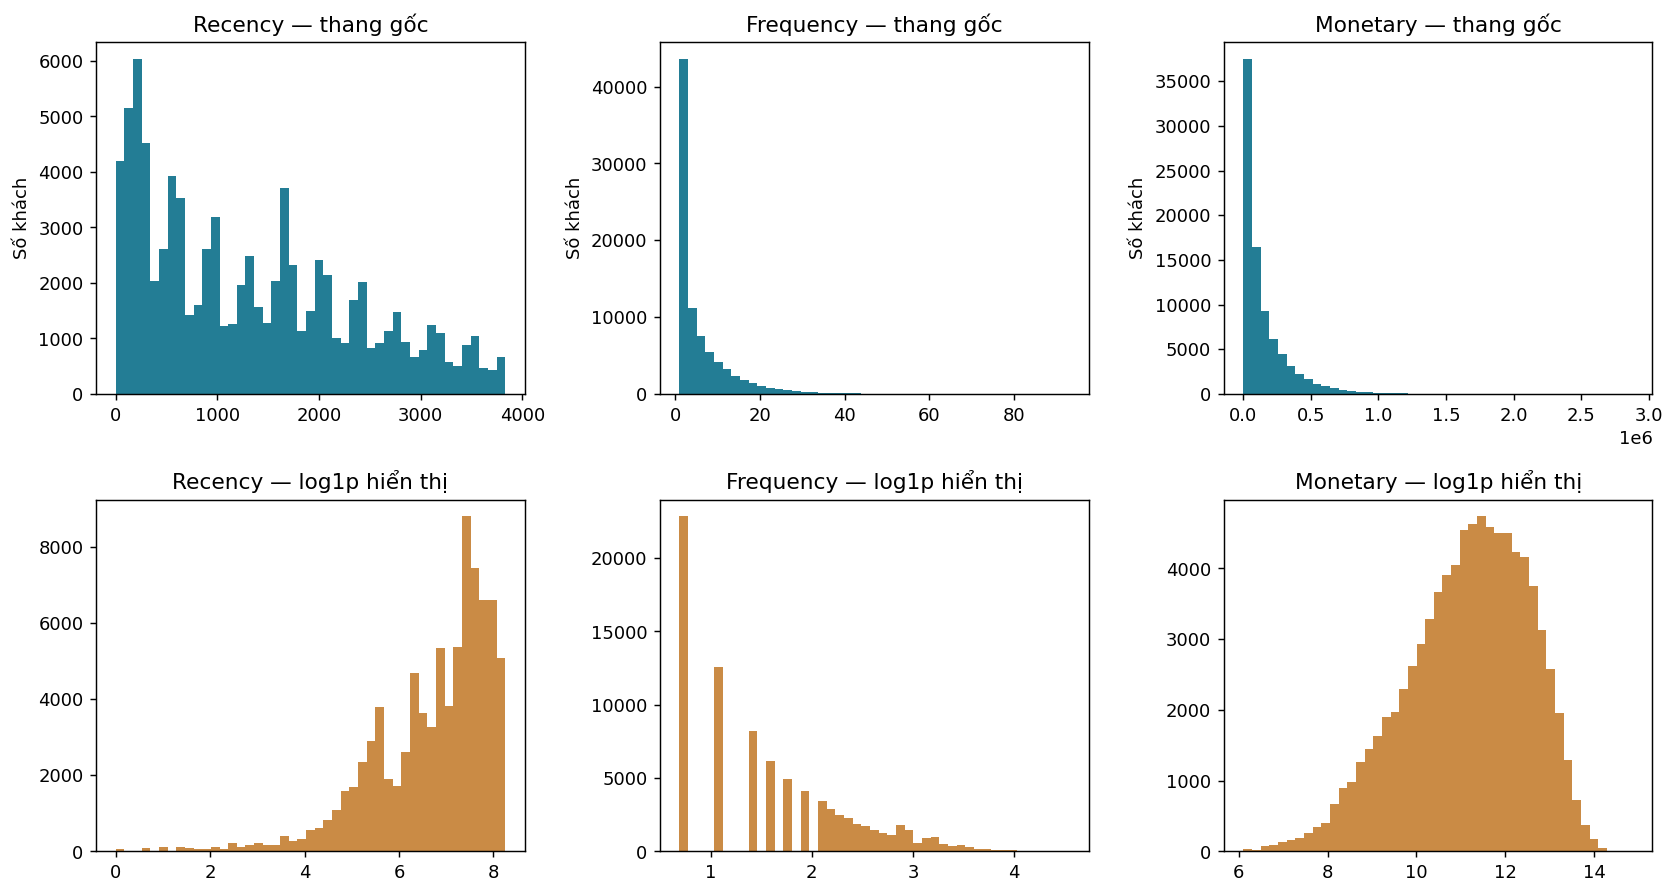

Độ lệch F/M cần đọc cùng P99/max; log nén đuôi, không sửa lỗi nguồn và không bảo đảm tạo cụm tốt hơn.

In [3]:
f=study.f.copy();summary=study.table('rfm_distribution','Thống kê RFM',distribution(f))
fig,axes=plt.subplots(2,3,figsize=(13,7))
for j,col in enumerate(FEATURES):
 values=f[col].astype(float);axes[0,j].hist(values,bins=45,color='#237d95');axes[0,j].set(title=col+' — thang gốc',ylabel='Số khách');axes[1,j].hist(np.log1p(values),bins=45,color='#ca8b45');axes[1,j].set(title=col+' — log1p hiển thị')
study.fig('rfm_histograms','Phân bố gốc và log hiển thị',fig)
study.note('Độ lệch F/M cần đọc cùng P99/max; log nén đuôi, không sửa lỗi nguồn và không bảo đảm tạo cụm tốt hơn.')

## PC02.2 — Khách một đơn: quy mô và đóng góp

Đọc hai tỷ trọng riêng: số khách của mỗi nhóm tần suất chia tổng khách được phân tích; và tổng Monetary của nhóm đó chia tổng Monetary toàn tập. Hai tỷ trọng có thể rất khác nhau. Ví dụ nhóm chiếm một nửa số khách vẫn có thể chỉ đóng góp một phần nhỏ giá trị mua.

Các nhóm một đơn, 2–3, 4–7, 8–15 và từ 16 đơn trở lên không trùng nhau. Vì vậy, tỷ trọng khách cộng thành 100%; tỷ trọng Monetary cũng cộng thành 100%, trừ sai số hiển thị.

Khách một đơn chưa có hai lần mua để tính khoảng cách giữa các lần mua. Với khách nhiều đơn, chỉ tiêu khoảng cách bình quân trong bảng là thời gian từ đơn đầu đến đơn cuối chia số khoảng giữa các đơn; nhiều đơn cùng ngày có thể tạo khoảng bằng 0. Không gọi chỉ tiêu này là chu kỳ mua tương lai.


,frequency_band,Số khách,Tổng Net,R trung vị,F trung vị,M trung vị,Tỷ trọng khách,Tỷ trọng Net
0,1 đơn,22843,5.480755e+08,2342.0,1.0,16636.000,0.268378,0.043782
1,2–3 đơn,20746,1.174401e+09,1621.0,2.0,48922.155,0.243741,0.093816
2,4–7 đơn,18629,2.364555e+09,888.0,5.0,118657.080,0.218869,0.188890
3,8–15 đơn,15062,3.991445e+09,474.5,10.0,254429.310,0.176961,0.318852
4,16+ đơn,7835,4.439699e+09,230.0,21.0,522832.940,0.092052,0.354660


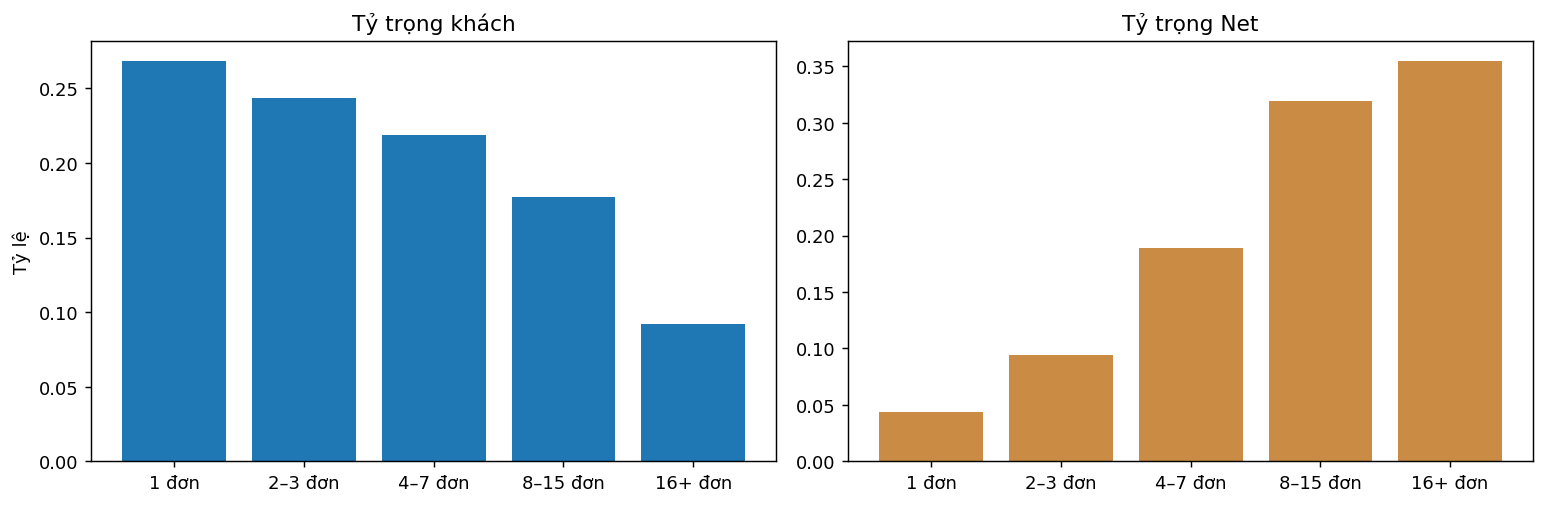

Có 22,843 khách một đơn (26.84%), đóng góp 4.38% Net. Không tính mean_gap=0 cho nhóm này; chưa quan sát lần mua thứ hai.

In [4]:
f['frequency_band']=pd.cut(f.Frequency,[0,1,3,7,15,np.inf],labels=['1 đơn','2–3 đơn','4–7 đơn','8–15 đơn','16+ đơn'])
t=study.table('frequency_bands','Quy mô và đóng góp theo Frequency',share_table(f,'frequency_band'))
fig,axes=plt.subplots(1,2,figsize=(12,4));axes[0].bar(t.frequency_band.astype(str),t.customer_share);axes[0].set(title='Tỷ trọng khách',ylabel='Tỷ lệ');axes[1].bar(t.frequency_band.astype(str),t.Monetary_share,color='#ca8b45');axes[1].set(title='Tỷ trọng Net');study.fig('frequency_contribution','Khách và Net theo số đơn',fig)
one=f.Frequency.eq(1);study.note(f'Có {one.sum():,} khách một đơn ({one.mean():.2%}), đóng góp {float(sum(f.loc[one,"Monetary"],Decimal(0))/sum(f.Monetary,Decimal(0))):.2%} Net. Không tính mean_gap=0 cho nhóm này; chưa quan sát lần mua thứ hai.')

## PC02.3 — Recency và hoạt động gần cuối kỳ

Chia Recency thành các khoảng ngày để dễ đọc. Recency nhỏ nghĩa là ngày đặt đơn delivered gần mốc 31/12/2022 hơn. Những nhóm ngày không trùng nhau và bao phủ toàn bộ khách đủ điều kiện.

So số khách với Monetary của từng khoảng. Monetary là giá trị tích lũy cả lịch sử, nên khách lâu chưa mua vẫn có thể đóng góp nhiều trong quá khứ. Không dùng số tiền tích lũy để khẳng định khách hiện đang hoạt động tốt, và chưa gọi khách Recency cao là đã rời bỏ.


,recency_band,Số khách,Tổng Net,R trung vị,F trung vị,M trung vị,Tỷ trọng khách,Tỷ trọng Net
0,0–30,1769,5.874104e+08,11.0,11.0,260516.650,0.020784,0.046925
1,31–90,2591,8.961750e+08,62.0,11.0,278993.270,0.030441,0.071590
2,91–180,5414,1.636440e+09,132.0,10.0,238267.740,0.063608,0.130725
3,181–365,10658,2.764691e+09,251.0,8.0,202484.695,0.125219,0.220854
4,366–730,12187,2.484984e+09,556.0,7.0,157942.000,0.143183,0.198510
5,731+,52496,4.148475e+09,1804.0,2.0,45971.615,0.616766,0.331396


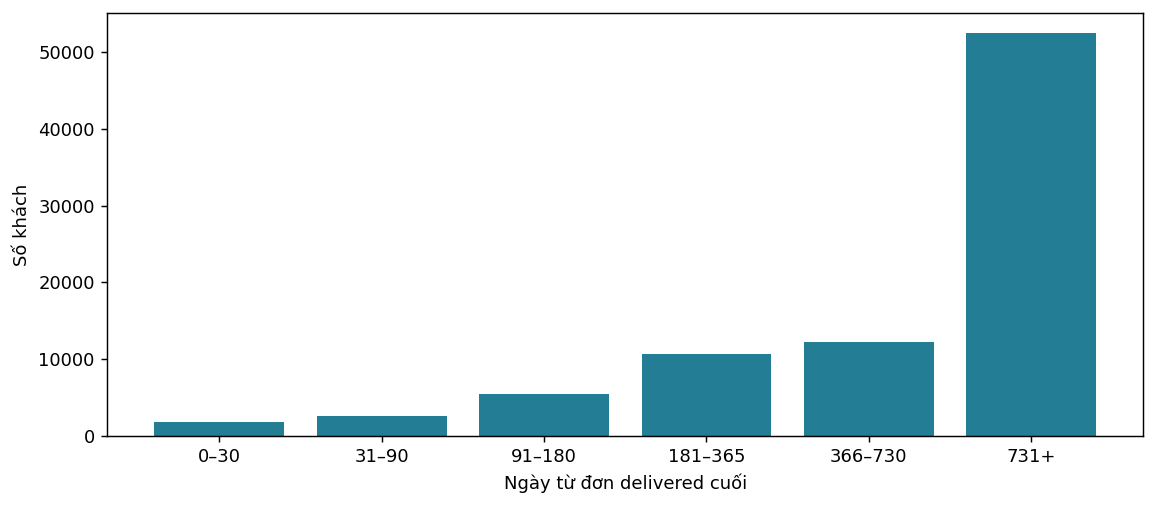

Net là tích lũy toàn lịch sử: khách lâu chưa mua vẫn có thể đóng góp lớn trong quá khứ. Không dùng M tích lũy để chứng minh đang hoạt động tốt.

In [5]:
f['recency_band']=pd.cut(f.Recency,[-1,30,90,180,365,730,np.inf],labels=['0–30','31–90','91–180','181–365','366–730','731+'])
t=study.table('recency_bands','Khách và Net theo Recency',share_table(f,'recency_band'))
fig,ax=plt.subplots(figsize=(9,4));ax.bar(t.recency_band.astype(str),t.customers,color='#237d95');ax.set(xlabel='Ngày từ đơn delivered cuối',ylabel='Số khách');study.fig('recency_bands','Phân bố nhóm Recency',fig)
study.note('Net là tích lũy toàn lịch sử: khách lâu chưa mua vẫn có thể đóng góp lớn trong quá khứ. Không dùng M tích lũy để chứng minh đang hoạt động tốt.')

## PC02.4 — Mức tập trung Monetary và đường tích lũy

Sắp khách theo Monetary giảm dần. Lấy lần lượt nhóm 1%, 5%, 10%, 20% và 50% đứng đầu; cộng Monetary của mỗi nhóm rồi so với tổng Monetary toàn tập. Nếu nhóm 10% đóng góp phần lớn tổng tiền thì giá trị mua đang tập trung ở một số ít khách.

Đường tích lũy cho thấy giá trị tăng lên thế nào khi thêm khách. Đường chéo là trường hợp mọi khách đóng góp như nhau, không phải mục tiêu bắt buộc. Đây là mô tả tiền mua tích lũy; chưa phản ánh lợi nhuận, rủi ro hoặc mức đóng góp trong tương lai.


,top_customer_fraction,selected_customers,monetary_share
0,0.01,852,0.070663
1,0.05,4256,0.242350
2,0.10,8512,0.391048
3,0.20,17023,0.595130
4,0.50,42558,0.889816


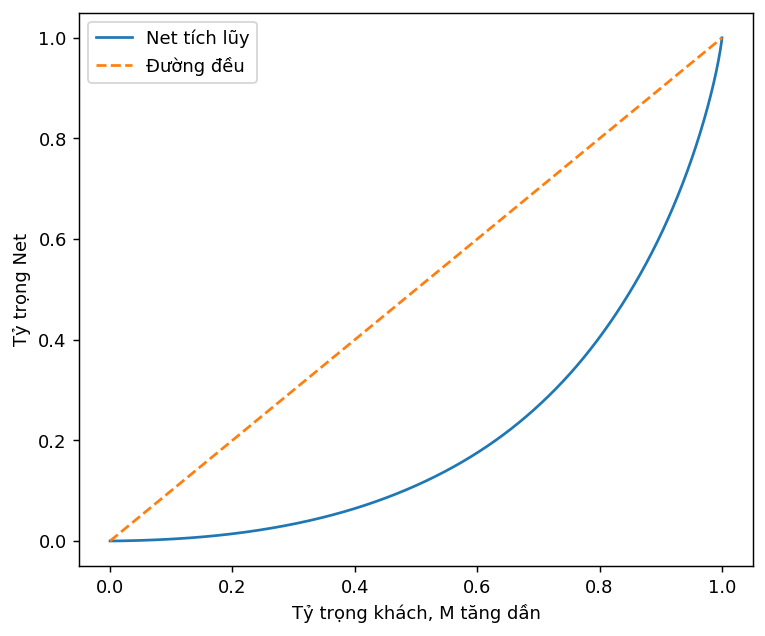

Top10% khách (làm tròn số khách lên) đóng góp 39.10% Net. Đây là tập trung giá trị giao dịch, chưa phải lợi nhuận/CLV.

In [6]:
top=study.table('monetary_concentration','Mức độ tập trung Net',concentration(f))
v=np.sort(f.Monetary.astype(float).to_numpy());cum=np.r_[0,np.cumsum(v)/v.sum()];x=np.linspace(0,1,len(cum))
fig,ax=plt.subplots(figsize=(6,5));ax.plot(x,cum,label='Net tích lũy');ax.plot([0,1],[0,1],'--',label='Đường đều');ax.set(xlabel='Tỷ trọng khách, M tăng dần',ylabel='Tỷ trọng Net');ax.legend();study.fig('lorenz','Đường tập trung Monetary',fig)
study.note(f'Top10% khách (làm tròn số khách lên) đóng góp {top.loc[top.top_customer_fraction.eq(.1),"monetary_share"].iloc[0]:.2%} Net. Đây là tập trung giá trị giao dịch, chưa phải lợi nhuận/CLV.')

## PC02.5 — Quan hệ giữa đặc trưng và cơ hội được quan sát

Khách nhiều đơn thường có nhiều cơ hội tích lũy Monetary và mua nhiều sản phẩm khác nhau. Vì vậy cần xem mối liên hệ giữa số đơn, tiền mua và độ dài lịch sử quan sát trước khi đặt tên nhóm là trung thành hoặc có tiềm năng cao.

Bảng tương quan Spearman cho biết các biến có xu hướng tăng/giảm cùng nhau theo thứ hạng hay không. Nó không chứng minh biến này gây ra biến kia. Thời gian từ đơn đầu đến đơn cuối chỉ là khoảng lịch sử ghi nhận được; chưa xác nhận đầy đủ thời gian khách có cơ hội mua hoặc mua ngoài hệ thống.


,Đặc trưng,Recency (ngày),Frequency (đơn),Monetary (ĐVT nguồn),observed_span_days
0,Recency,1.000000,-0.648940,-0.621314,-0.783065
1,Frequency,-0.648940,1.000000,0.899148,0.897844
2,Monetary,-0.621314,0.899148,1.000000,0.808885
3,observed_span_days,-0.783065,0.897844,0.808885,1.000000


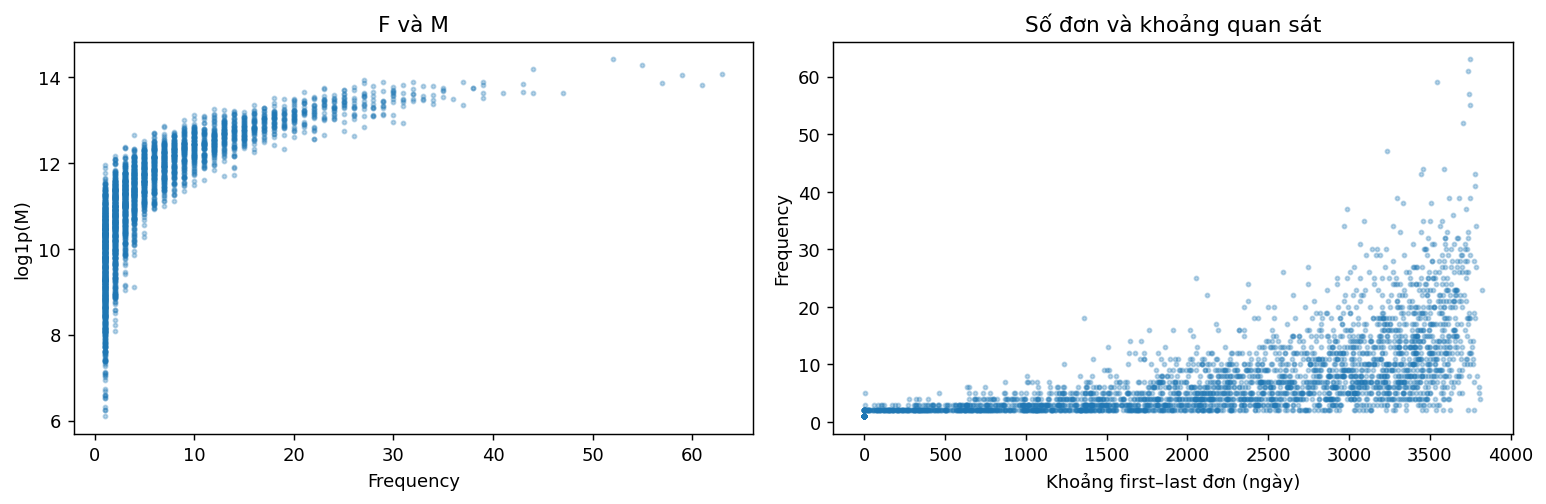

Spearman(F,M)=0.899; Spearman(F,khoảng quan sát)=0.898. Không suy nguyên nhân, không chia F cho khoảng first–last để gọi là tần suất năm khi nhiều khách có span=0.

In [7]:
corr=f[FEATURES+['observed_span_days']].astype(float).corr(method='spearman')
study.table('spearman','Tương quan Spearman',corr.reset_index(names='Đặc trưng'))
rng=np.random.default_rng(42);sample=f.iloc[rng.choice(len(f),min(4000,len(f)),replace=False)]
fig,axes=plt.subplots(1,2,figsize=(12,4));axes[0].scatter(sample.Frequency,np.log1p(sample.Monetary.astype(float)),s=5,alpha=.3);axes[0].set(xlabel='Frequency',ylabel='log1p(M)',title='F và M');axes[1].scatter(sample.observed_span_days,sample.Frequency,s=5,alpha=.3);axes[1].set(xlabel='Khoảng first–last đơn (ngày)',ylabel='Frequency',title='Số đơn và khoảng quan sát');study.fig('rfm_relationships','Quan hệ giữa các đặc trưng',fig)
study.note(f'Spearman(F,M)={corr.loc["Frequency","Monetary"]:.3f}; Spearman(F,khoảng quan sát)={corr.loc["Frequency","observed_span_days"]:.3f}. Không suy nguyên nhân, không chia F cho khoảng first–last để gọi là tần suất năm khi nhiều khách có span=0.')

## PC02.6 — Ngoại lệ: phát hiện để hiểu, không tự động xóa

Kiểm tra những khách có Frequency hoặc Monetary cao và đối chiếu đơn nguồn. Nếu tăng tiền do ghép bảng hoặc bản ghi sai thì cần xử lý bằng bằng chứng; nếu khách thực sự mua nhiều thì giữ lại. Không xóa khách chỉ vì làm biểu đồ dài đuôi hoặc làm cụm khó tách.

P99 là mốc tham khảo để đọc phần đuôi, không phải ranh giới tự động giữa đúng và sai. Phương án chính không cắt ngọn khách hợp lệ. Ảnh hưởng của việc giới hạn giá trị lớn được thử riêng trên bản sao trong PC05 và không sửa dữ liệu chính.


In [8]:
rows=[]
for col in FEATURES:
 values=f[col].astype(float);q1,q3=values.quantile([.25,.75]);p99=values.quantile(.99);upper=q3+1.5*(q3-q1)
 rows.append({'Đặc trưng':col,'P99':p99,'Vượt P99':int((values>p99).sum()),'Ngưỡng IQR trên':upper,'Vượt IQR trên':int((values>upper).sum()),'Max':values.max()})
study.table('tail_audit','Các ngưỡng mô tả đuôi',pd.DataFrame(rows))
study.table('top_monetary_cases','Khách giá trị cao — mẫu rà soát',f.sort_values('Monetary',ascending=False)[['customer_id','Recency','Frequency','Monetary','observed_span_days']].head(10))
study.note('Một khách có thể vượt nhiều ngưỡng; không cộng các số đếm thành tổng lỗi. Chưa có bằng chứng để cap/xóa. PC03 so log(F,M) với giữ gốc thay vì tự loại khách.')

,Đặc trưng,P99,Vượt P99,Ngưỡng IQR trên,Vượt IQR trên,Max
0,Recency,3702.000,846,4522.5000,0,3832.00
1,Frequency,34.000,754,18.5000,5262,93.00
2,Monetary,829222.161,852,452904.7275,5785,2883271.24


,Mã khách,Recency (ngày),Frequency (đơn),Monetary (ĐVT nguồn),observed_span_days
22644,13699,54,63,2883271.24,3736
22642,13698,99,60,2645159.86,3666
24418,139815,142,56,2485251.47,3569
24417,139814,200,63,2386534.97,3534
22638,13697,125,58,2297804.75,3633
22652,13700,75,49,2110727.60,3712
22660,13701,77,50,2109379.61,3709
24416,139813,125,59,2083934.85,3684
24415,139812,213,48,1988430.19,3589
24420,139817,140,55,1914807.31,3664


Một khách có thể vượt nhiều ngưỡng; không cộng các số đếm thành tổng lỗi. Chưa có bằng chứng để cap/xóa. PC03 so log(F,M) với giữ gốc thay vì tự loại khách.

## PC02.7 — Log, StandardScaler và ý nghĩa khoảng cách

StandardScaler xử lý từng cột riêng:

$$z=\frac{x-\mu}{\sigma}$$

Trong công thức này, x là giá trị gốc của một khách ở một cột; $\mu$ là trung bình của cột đó; $\sigma$ là độ lệch chuẩn của cột; z là giá trị sau chuẩn hóa. Giá trị sau chuẩn hóa biểu thị vị trí so với trung bình theo đơn vị độ lệch chuẩn, không phải điểm chất lượng khách hàng.

StandardScaler dùng độ lệch chuẩn theo quy ước ddof=0.

Log nén bớt chênh lệch giữa các giá trị lớn:

$$log1p(x)=\ln(1+x)$$

x ở đây là Frequency hoặc Monetary; ln là log tự nhiên. Cộng 1 cho phép xử lý giá trị bằng 0. Log giữ thứ tự lớn/nhỏ nhưng thay đổi khoảng cách; không phải sửa số tiền gốc.

| Thử nghiệm | Thứ tự xử lý |
|---|---|
| TN1 | Chuẩn hóa cả Recency, Frequency và Monetary gốc |
| TN2 | Log Frequency và Monetary, sau đó chuẩn hóa cả ba cột; Recency không lấy log |

Chuẩn hóa không tự tạo phân phối chuẩn hoặc xóa ngoại lệ. Log chưa chắc tốt hơn; hai cách phải được đối chiếu bằng kết quả mô hình.


,Thí nghiệm,Đặc trưng,Mean,Std,P99,Max
0,TN1,Recency,-9.216227e-17,1.0,2.307080,2.433373
1,TN1,Frequency,-3.472781e-17,1.0,3.966737,12.346406
2,TN1,Monetary,-6.945563e-17,1.0,3.791054,15.206473
3,TN2,Recency,-9.216227e-17,1.0,2.307080,2.433373
4,TN2,Frequency,6.117438e-16,1.0,2.435678,3.668303
5,TN2,Monetary,-7.613405e-16,1.0,1.793137,2.694159


C:\Users\trant\AppData\Local\Temp\ipykernel_32076\249566111.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  for ax,name,z in [(axes[0],'TN1',z1),(axes[1],'TN2',z2)]:ax.boxplot(z,labels=FEATURES,showfliers=False);ax.set(title=name+' — ẩn điểm ngoài box chỉ để đọc hình',ylabel='Giá trị chuẩn hóa')
C:\Users\trant\AppData\Local\Temp\ipykernel_32076\249566111.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  for ax,name,z in [(axes[0],'TN1',z1),(axes[1],'TN2',z2)]:ax.boxplot(z,labels=FEATURES,showfliers=False);ax.set(title=name+' — ẩn điểm ngoài box chỉ để đọc hình',ylabel='Giá trị chuẩn hóa')


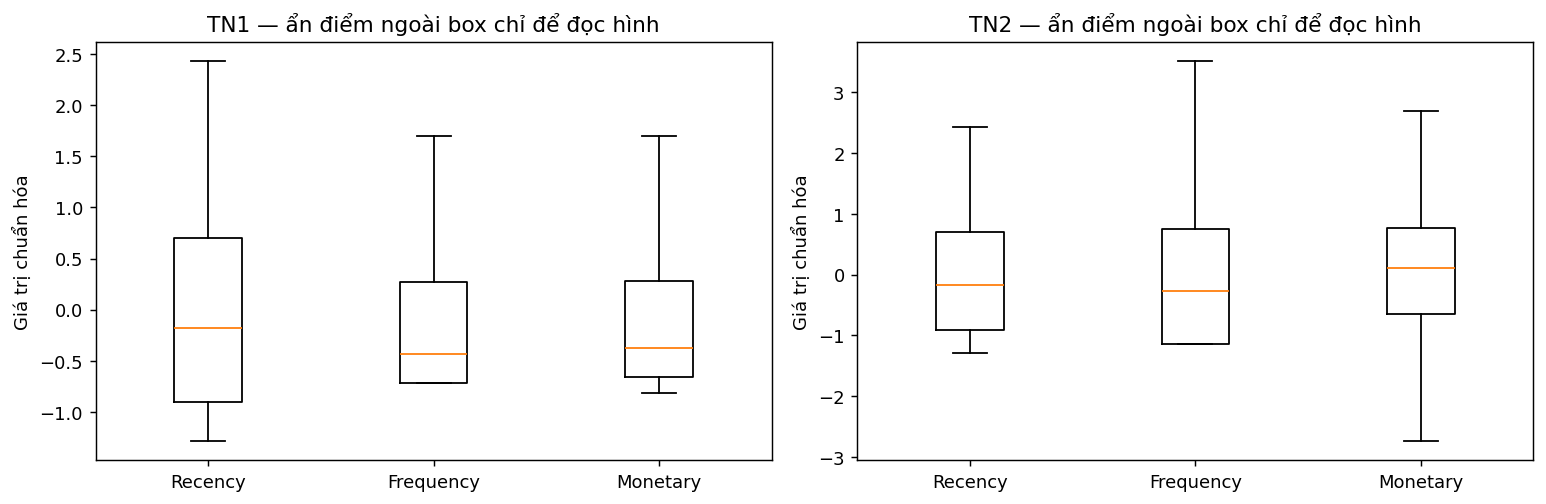

Ví dụ khoảng cách Euclid giữa khách M lớn nhất và khách gần trung vị M: TN1=17.701, TN2=4.148. Đây là minh họa biến đổi khoảng cách, không chứng minh cặp nào quan trọng hơn.

In [10]:
z1,s1=feature_matrix(f,'TN1');z2,s2=feature_matrix(f,'TN2')
stats=[]
for name,z in [('TN1',z1),('TN2',z2)]:
 for j,col in enumerate(FEATURES):stats.append({'Thí nghiệm':name,'Đặc trưng':col,'Mean':z[:,j].mean(),'Std':z[:,j].std(),'P99':np.quantile(z[:,j],.99),'Max':z[:,j].max()})
study.table('scaled_summary','Thang đo sau biến đổi',pd.DataFrame(stats))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,name,z in [(axes[0],'TN1',z1),(axes[1],'TN2',z2)]:ax.boxplot(z,labels=FEATURES,showfliers=False);ax.set(title=name+' — ẩn điểm ngoài box chỉ để đọc hình',ylabel='Giá trị chuẩn hóa')
study.fig('transformed_boxplots','Thang đo hai thí nghiệm',fig)
hi=f.Monetary.astype(float).idxmax();med=(f.Monetary.astype(float)-f.Monetary.astype(float).median()).abs().idxmin()
study.note(f'Ví dụ khoảng cách Euclid giữa khách M lớn nhất và khách gần trung vị M: TN1={np.linalg.norm(z1[hi]-z1[med]):.3f}, TN2={np.linalg.norm(z2[hi]-z2[med]):.3f}. Đây là minh họa biến đổi khoảng cách, không chứng minh cặp nào quan trọng hơn.')

## PC02.8 — Đặc trưng hành vi và quyết định sử dụng

RFM là đầu vào chính. Tỷ lệ hủy/trả, số sản phẩm khác nhau, giá trị đơn trung bình và số lượng mua mỗi đơn dùng để giải thích nhóm sau phân cụm.

Tỷ lệ hủy của một khách được tính từ đơn hủy chia toàn bộ đơn của chính khách đó trong phạm vi ngày. Giá trị đơn trung bình lấy Monetary chia số đơn delivered. Nhiều biến được suy từ RFM nên đưa thêm có thể lặp thông tin và tăng ảnh hưởng của cùng một hành vi.

Muốn mở rộng đặc trưng cần lý do nghiệp vụ, kiểm tra độ trùng thông tin, cách chuẩn hóa và một thí nghiệm riêng. Các trạng thái nguồn chỉ mô tả bản ghi đang có, không tự xác nhận ý định hoặc lỗi của khách.


In [11]:
b=study.behavior[study.behavior.customer_id.isin(f.customer_id)].copy()
cols=['total_orders','cancelled_share','returned_share','return_detail_share','average_order_value','distinct_products','delivered_missing_shipment_share']
study.table('behavior_summary','Đặc trưng hành vi trên tập RFM',b[cols].describe(percentiles=[.5,.9,.99]).T.reset_index(names='Đặc trưng'))
choices=pd.DataFrame([{'Đặc trưng':'R,F,M','Vai trò':'Phân cụm chính','Lý do':'Ba trục giá trị và hoạt động rõ ràng'}, {'Đặc trưng':'AOV, số SP','Vai trò':'Mô tả cụm trước','Lý do':'Phụ thuộc M/F và số lần mua'}, {'Đặc trưng':'Hủy/trả','Vai trò':'Mô tả, kiểm độ nhạy','Lý do':'Snapshot, chưa xác minh chuyển trạng thái'}, {'Đặc trưng':'signup/tenure','Vai trò':'Chưa dùng','Lý do':'Ý nghĩa signup còn giới hạn'}, {'Đặc trưng':'mean_gap','Vai trò':'Mô tả có điều kiện','Lý do':'Không có ở khách một đơn'}])
study.table('feature_decisions','Quyết định đặc trưng cho PC03',choices)
study.note('Bàn giao: TN1/TN2 trên cùng khách, không cap/xóa; các đặc trưng bổ trợ chưa là biến đầu vào. Nếu mở rộng phải chạy một thí nghiệm riêng trên cùng tập khách và kiểm trùng thông tin.')

,Đặc trưng,count,mean,std,min,50%,90%,99%,max
0,total_orders,85115.0,7.532456,8.753473,1.00,4.00,19.000000,42.0000,107.00
1,cancelled_share,85115.0,0.070507,0.119116,0.00,0.00,0.250000,0.5000,0.80
2,returned_share,85115.0,0.042562,0.093204,0.00,0.00,0.142857,0.5000,0.75
3,return_detail_share,85115.0,0.042478,0.093092,0.00,0.00,0.142857,0.5000,0.75
4,average_order_value,85115.0,24062.749594,15090.592554,445.65,22071.86,40968.788000,79123.4276,202022.56
5,distinct_products,85115.0,6.411067,7.273301,1.00,4.00,16.000000,35.0000,91.00
6,delivered_missing_shipment_share,85115.0,0.001006,0.020640,0.00,0.00,0.000000,0.0000,1.00


,Đặc trưng,Vai trò,Lý do
0,"R,F,M",Phân cụm chính,Ba trục giá trị và hoạt động rõ ràng
1,"AOV, số SP",Mô tả cụm trước,Phụ thuộc M/F và số lần mua
2,Hủy/trả,"Mô tả, kiểm độ nhạy","Snapshot, chưa xác minh chuyển trạng thái"
3,signup/tenure,Chưa dùng,Ý nghĩa signup còn giới hạn
4,mean_gap,Mô tả có điều kiện,Không có ở khách một đơn


Bàn giao: TN1/TN2 trên cùng khách, không cap/xóa; các đặc trưng bổ trợ chưa là biến đầu vào. Nếu mở rộng phải chạy một thí nghiệm riêng trên cùng tập khách và kiểm trùng thông tin.

In [12]:
study.note("### Kết luận nghiệp vụ PC02 và giả thuyết cần kiểm tra")
t=concentration(study.f);one=study.f.Frequency.eq(1)
study.note(f'Khách một đơn chiếm {one.mean():.2%}. Top10% theo M đóng góp {t.loc[t.top_customer_fraction.eq(.1),"monetary_share"].iloc[0]:.2%} Net. Điều đó cho thấy cần đọc đồng thời quy mô khách và tập trung giá trị, không chỉ trung bình. Dùng TN1 làm đối chứng thang gốc chuẩn hóa và TN2 kiểm ảnh hưởng nén F/M; chưa có căn cứ xóa khách đuôi. Các biến hủy/trả/giỏ hàng bổ trợ diễn giải chứ chưa được đưa vào khoảng cách.')

### Kết luận nghiệp vụ PC02 và giả thuyết cần kiểm tra

Khách một đơn chiếm 26.84%. Top10% theo M đóng góp 39.10% Net. Điều đó cho thấy cần đọc đồng thời quy mô khách và tập trung giá trị, không chỉ trung bình. Dùng TN1 làm đối chứng thang gốc chuẩn hóa và TN2 kiểm ảnh hưởng nén F/M; chưa có căn cứ xóa khách đuôi. Các biến hủy/trả/giỏ hàng bổ trợ diễn giải chứ chưa được đưa vào khoảng cách.

In [13]:
part_manifest=study.finish()

## Tài liệu phương pháp và phạm vi tham khảo

- [scikit-learn: K-Means và tổng quan phân cụm](https://scikit-learn.org/stable/modules/clustering.html#k-means).
- [StandardScaler: công thức và quy ước phương sai](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).
- [Silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).
- [Davies–Bouldin](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.davies_bouldin_score.html).
- [Adjusted Rand Index](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html).
